<a href="https://colab.research.google.com/github/Cintya-rdev/ml-primeiro-modelo/blob/main/Gerador_Dataset_Sintetico_MVP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gerador de dataset sintético: MVP (fermentação escura em batelada)

**Para que serve:** testar e depurar a pipeline (pré-processamento, modelos, validação, SHAP). **Não é resultado científico.**

- Uma linha = uma réplica de um ensaio em batelada. Cada condição tem 3 réplicas (`id_condicao` identifica o grupo).
- **7 features:** tipo de substrato, origem do inóculo, tipo de pré-tratamento, concentração de substrato (g SV/L), relação I/S (g SV inóculo/g SV substrato), pH inicial, temperatura (°C).
- **Alvo (Y04):** produção específica de H₂, em mL de H₂ por g SV de substrato adicionado.
- Metadados (não são features): lote do inóculo, concentração de inóculo, volumes, duração do ensaio.

**Como foi calibrado:** as medianas de Y04 do lignocelulósico (72 mL/g) e do efluente (113 mL/g) e a forma da resposta ao pH vêm da base pública harmonizada (subconjunto em batelada). Tudo que está marcado como **PRIOR** não tem dado de apoio e deve ser revisado.

**Atenção (circularidade):** as regras abaixo, inclusive a interação pH × I/S, são injetadas por mim. Um modelo treinado aqui vai reaprendê-las, e o SHAP vai "confirmá-las". Isso valida a pipeline, não a biologia.

In [10]:
# 1) Configuração
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc

SEED = 42             # reprodutibilidade
N_COND = 400          # nº de condições distintas (múltiplo de 4)
N_REP = 3             # réplicas por condição (triplicata)
TAXA_OUTLIER = 0.01   # fração de réplicas com falha (vazamento, erro de leitura)
TAXA_AUSENTE = 0.0    # fração de valores ausentes nas features (0 = nenhum)
Y_MAX = 450.0         # teto físico (mL H2/g): limite de Thauer, 4 mol/mol hexose ≈ 498 mL/g glicose
rng = np.random.default_rng(SEED)

In [11]:
# 2) Parâmetros (o que é dado e o que é PRIOR)
SUBSTRATOS = ["lignocelulosico", "glicerol", "vinhaca", "efluente"]

# Mediana alvo de Y04 (mL H2/g SV) no desenho amostral
ALVO_MEDIANA = {
    "lignocelulosico": 72,   # BASE PÚBLICA: mediana de 32 registros em batelada
    "efluente": 113,         # BASE PÚBLICA: mediana de 8 registros (n pequeno)
    "glicerol": 120,         # PRIOR: a base pública tem 0 registros em batelada  [A CALIBRAR]
    "vinhaca": 90,           # PRIOR: a base pública tem 1 registro               [A CALIBRAR]
}

# Multiplicadores (PRIOR, sem dado de apoio)                                       [A CALIBRAR]
INOCULOS = {"lodo_UASB": 1.00, "lodo_esgoto": 0.85, "composto": 0.70, "cultura_enriquecida": 1.25}
PRETRAT = {"nenhum": 1.0, "acido": 1.5, "alcalino": 1.7, "DES": 1.6, "autoclave": 1.2}  # só lignocelulósico
PRETRAT_PROB = [0.25, 0.20, 0.20, 0.20, 0.15]

# Temperaturas usadas (°C) e frequência (maioria mesofílica)
T_NIVEIS = [30, 35, 37, 40, 55, 60]
T_PROB   = [0.05, 0.25, 0.45, 0.10, 0.12, 0.03]   # Liu et al. (2026): 20-52 °C, média 36.8

# Faixas do desenho: pH inicial 4.5-7.5; conc. 5-40 g SV/L (Liu et al. 2026: 9-56 g/L); I/S 0.1-3.0 (escala log)
PH_OTIMO = 6.2   # base pública: maior mediana em 6.0-6.5. Liu et al. (2026) citam ótimo 5.0-5.5 em açúcares  [A CALIBRAR]
IS_MIN, IS_MAX = 0.1, 3.0

# Fontes de variabilidade
SIGMA_LOTE = 0.10      # efeito de lote do inóculo (lognormal)
SIGMA_MODELO = 0.20    # variação da condição não explicada pelas features
SIGMA_REPLICATA = 0.10 # CV de réplica ~10%
RUIDO_ADIT = 3.0       # ruído aditivo (mL/g), deixa os valores baixos ruidosos

In [12]:
# 3) Funções de resposta (cada fator vale 0-1, exceto temperatura termofílica)

def f_ph(ph, i_s):
    # pH ótimo = PH_OTIMO. Colapso abaixo de ~5 e platô ~0.55 acima do ótimo (base pública).
    # O ótimo se desloca ±0.2 com I/S (interação injetada).
    # INTERAÇÃO injetada (PRIOR): com I/S baixo (carga alta) o ótimo sobe e a queda abaixo dele é mais íngreme.
    ph_opt = PH_OTIMO + 0.20 * np.clip(np.log(0.5 / i_s) / 1.6, -0.5, 1.0)
    w_low = 1.0 * (0.75 + 0.25 * np.clip(i_s / 0.5, 0, 1.5))
    baixo = np.exp(-((ph - ph_opt) / w_low) ** 2)
    alto = 0.55 + 0.45 * np.exp(-((ph - ph_opt) / 0.25) ** 2)
    return np.where(ph < ph_opt, baixo, alto)

def f_temp(t):
    # mesofílica (pico 37 °C) e termofílica (pico 55 °C, 1.6x). Base pública: mediana termofílica ~2x a mesofílica,
    # mas confundida com substrato; usei 1.6 para não superestimar.
    meso = np.exp(-((t - 37) / 8) ** 2)
    termo = 1.6 * np.exp(-((t - 55) / 5) ** 2)
    return np.maximum(meso, termo)

def f_is(i_s):
    # ótimo em I/S = 0.5 (S/I = 2). Pouco inóculo (carga alta) penaliza mais que muito inóculo.  PRIOR
    z = np.log(i_s / 0.5)
    return np.where(z < 0, np.exp(-(z / 1.0) ** 2), np.exp(-(z / 1.6) ** 2))

def f_conc(c):
    # satura em baixa concentração e há inibição por substrato acima de ~15 g SV/L.  PRIOR
    return (1 - np.exp(-c / 4.0)) * np.exp(-(np.maximum(0, c - 15) / 20) ** 2)

def sortear_desenho(n, seed):
    # LHS separado por substrato: cada substrato cobre todo o espaço de condições
    assert n % len(SUBSTRATOS) == 0, "N_COND deve ser múltiplo de 4"
    r = np.random.default_rng(seed)
    m = n // len(SUBSTRATOS)
    cum = np.cumsum(T_PROB) / np.sum(T_PROB)
    partes = []
    for j, sub in enumerate(SUBSTRATOS):
        u = qmc.LatinHypercube(d=4, seed=seed + j).random(m)
        partes.append(pd.DataFrame({
            "tipo_substrato": sub,
            "origem_inoculo": r.choice(list(INOCULOS), m),
            "lote_inoculo": r.integers(1, 4, m),
            "tipo_pretratamento": (r.choice(list(PRETRAT), m, p=PRETRAT_PROB) if sub == "lignocelulosico"
                                   else np.array(["nenhum"] * m)),
            "conc_substrato_gsv_l": 5 + 35 * u[:, 2],
            "relacao_i_s": np.exp(np.log(IS_MIN) + (np.log(IS_MAX) - np.log(IS_MIN)) * u[:, 3]),
            "ph_inicial": 4.5 + 3.0 * u[:, 0],
            "temperatura_c": np.array(T_NIVEIS)[np.minimum(np.searchsorted(cum, u[:, 1]), len(T_NIVEIS) - 1)],
        }))
    return pd.concat(partes, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)

def resposta_base(d):
    return (d.tipo_pretratamento.map(PRETRAT).values * d.origem_inoculo.map(INOCULOS).values
            * f_ph(d.ph_inicial.values, d.relacao_i_s.values) * f_temp(d.temperatura_c.values)
            * f_is(d.relacao_i_s.values) * f_conc(d.conc_substrato_gsv_l.values))

In [13]:
# 4) Calibração por substrato e geração do dataset
# Escala de cada substrato: faz a mediana simulada coincidir com ALVO_MEDIANA no desenho amostral
cal = sortear_desenho(20000, SEED + 1)
raw = resposta_base(cal)
ESCALA = {s: ALVO_MEDIANA[s] / np.median(raw[cal.tipo_substrato.values == s]) for s in SUBSTRATOS}

des = sortear_desenho(N_COND, SEED)
des.insert(0, "id_condicao", np.arange(1, N_COND + 1))

lote_ef = {(o, l): rng.lognormal(0, SIGMA_LOTE) for o in INOCULOS for l in (1, 2, 3)}
y_det = resposta_base(des) * des.tipo_substrato.map(ESCALA).values
y_det *= np.array([lote_ef[(o, l)] for o, l in zip(des.origem_inoculo, des.lote_inoculo)])
y_cond = y_det * rng.lognormal(0, SIGMA_MODELO, N_COND)          # variação da condição
# Reescala final por substrato: com poucas condições a mediana amostral oscila; aqui ela é fixada no alvo
for s_ in SUBSTRATOS:
    m_ = (des.tipo_substrato == s_).values
    y_cond[m_] *= ALVO_MEDIANA[s_] / np.median(y_cond[m_])

df = des.loc[des.index.repeat(N_REP)].reset_index(drop=True)      # triplicatas
df["replicata"] = np.tile(np.arange(1, N_REP + 1), N_COND)
y = np.repeat(y_cond, N_REP) * rng.lognormal(0, SIGMA_REPLICATA, len(df)) + rng.normal(0, RUIDO_ADIT, len(df))

falha = rng.random(len(df)) < TAXA_OUTLIER                        # falhas pontuais (vazamento, leitura)
y = np.where(falha, y * rng.choice([0.3, 2.0], len(df)), y)
y = np.clip(y, 0, Y_MAX)

# Metadados e colunas derivadas (NÃO são features)
df["conc_inoculo_gsv_l"] = df.relacao_i_s * df.conc_substrato_gsv_l       # X05, calculada
df["volume_reator_l"], df["volume_util_l"] = 0.25, 0.10                   # frasco único (constantes)
df["headspace_l"] = df.volume_reator_l - df.volume_util_l                 # X10, calculada
df["duracao_h"] = 48                                                      # fixa pelo protocolo
df["y04_ml_h2_por_g_sv"] = y.round(1)
df["y12_producao_final_ml"] = (y * df.conc_substrato_gsv_l * df.volume_util_l).round(1)
df["_verdade_outlier"] = falha        # só para auditoria: NÃO usar como feature

for c, nd in [("conc_substrato_gsv_l", 2), ("relacao_i_s", 2), ("ph_inicial", 2), ("conc_inoculo_gsv_l", 2)]:
    df[c] = df[c].round(nd)

FEATURES = ["tipo_substrato", "origem_inoculo", "tipo_pretratamento",
            "conc_substrato_gsv_l", "relacao_i_s", "ph_inicial", "temperatura_c"]
ALVO = "y04_ml_h2_por_g_sv"

if TAXA_AUSENTE > 0:
    for c in ["conc_substrato_gsv_l", "relacao_i_s", "ph_inicial", "temperatura_c"]:
        df.loc[rng.random(len(df)) < TAXA_AUSENTE, c] = np.nan

print(df.shape, "| condições:", df.id_condicao.nunique())
df.head()

(1200, 18) | condições: 400


,id_condicao,tipo_substrato,origem_inoculo,lote_inoculo,tipo_pretratamento,conc_substrato_gsv_l,relacao_i_s,ph_inicial,temperatura_c,replicata,conc_inoculo_gsv_l,volume_reator_l,volume_util_l,headspace_l,duracao_h,y04_ml_h2_por_g_sv,y12_producao_final_ml,_verdade_outlier
0,1,vinhaca,cultura_enriquecida,2,nenhum,6.57,1.41,5.64,37,1,9.29,0.25,0.1,0.15,48,314.7,206.7,False
1,1,vinhaca,cultura_enriquecida,2,nenhum,6.57,1.41,5.64,37,2,9.29,0.25,0.1,0.15,48,363.4,238.7,False
2,1,vinhaca,cultura_enriquecida,2,nenhum,6.57,1.41,5.64,37,3,9.29,0.25,0.1,0.15,48,97.6,64.1,True
3,2,vinhaca,composto,3,nenhum,28.36,0.12,6.06,37,1,3.54,0.25,0.1,0.15,48,40.6,115.3,False
4,2,vinhaca,composto,3,nenhum,28.36,0.12,6.06,37,2,3.54,0.25,0.1,0.15,48,51.4,145.9,False


Mediana de Y04 por substrato (mL H2/g SV): simulada x alvo
                 simulada  alvo
efluente            114.0   113
glicerol            124.0   120
lignocelulosico      72.0    72
vinhaca              85.0    90

Resposta ao pH (1.00 = faixa 6.0-6.5):
         base_publica_norm  simulado_norm
<=5.0                 0.09           0.20
5.0-5.5               0.71           0.67
5.5-6.0               0.86           0.96
6.0-6.5               1.00           1.00
6.5-7.0               0.62           0.89
>7.0                  0.62           0.85

A comparação é qualitativa: na base pública substrato e estudo estão misturados.


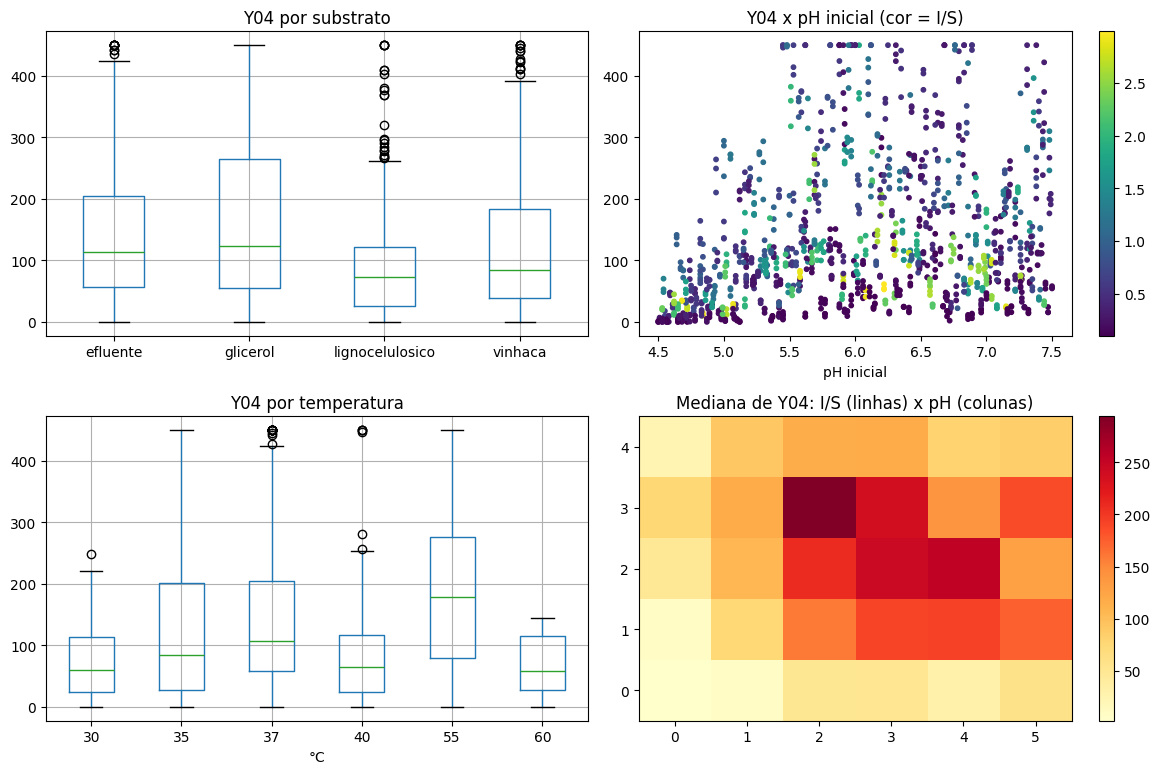

In [14]:
# 5) Verificações: o gerador reproduz o que veio da base pública?
print("Mediana de Y04 por substrato (mL H2/g SV): simulada x alvo")
print(pd.DataFrame({"simulada": df.groupby("tipo_substrato")[ALVO].median().round(0),
                    "alvo": pd.Series(ALVO_MEDIANA)}))

# Resposta ao pH, normalizada pelo pico, contra as medianas da base pública (batelada, todos os substratos)
PUB = {"<=5.0": 14, "5.0-5.5": 113, "5.5-6.0": 137, "6.0-6.5": 159, "6.5-7.0": 99, ">7.0": 98}
bins = pd.cut(df.ph_inicial, [0, 5, 5.5, 6, 6.5, 7, 14], labels=list(PUB))
sim = df.groupby(bins, observed=True)[ALVO].median()
cmp_ = pd.DataFrame({"base_publica_norm": pd.Series(PUB) / PUB["6.0-6.5"],
                     "simulado_norm": sim / sim["6.0-6.5"]}).round(2)
print("\nResposta ao pH (1.00 = faixa 6.0-6.5):"); print(cmp_)
print("\nA comparação é qualitativa: na base pública substrato e estudo estão misturados.")

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
df.boxplot(ALVO, by="tipo_substrato", ax=ax[0, 0]); ax[0, 0].set_title("Y04 por substrato"); ax[0, 0].set_xlabel("")
sc = ax[0, 1].scatter(df.ph_inicial, df[ALVO], c=df.relacao_i_s, cmap="viridis", s=10)
ax[0, 1].set_title("Y04 x pH inicial (cor = I/S)"); ax[0, 1].set_xlabel("pH inicial"); plt.colorbar(sc, ax=ax[0, 1])
df.boxplot(ALVO, by="temperatura_c", ax=ax[1, 0]); ax[1, 0].set_title("Y04 por temperatura"); ax[1, 0].set_xlabel("°C")
piv = df.assign(ph=pd.cut(df.ph_inicial, 6), is_=pd.qcut(df.relacao_i_s, 5)).pivot_table(
    index="is_", columns="ph", values=ALVO, aggfunc="median", observed=True)
im = ax[1, 1].imshow(piv.values, aspect="auto", origin="lower", cmap="YlOrRd")
ax[1, 1].set_title("Mediana de Y04: I/S (linhas) x pH (colunas)"); plt.colorbar(im, ax=ax[1, 1])
plt.suptitle(""); plt.tight_layout(); plt.show()

In [15]:
# 6) Teste rápido do MVP: baseline com validação cruzada AGRUPADA por condição
# (réplicas da mesma condição não podem ficar em folds diferentes, senão há vazamento)
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

cats = ["tipo_substrato", "origem_inoculo", "tipo_pretratamento"]
nums = [c for c in FEATURES if c not in cats]
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cats),
    ("num", make_pipeline(SimpleImputer(strategy="median")), nums),
])
modelo = Pipeline([("prep", prep), ("rf", RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1))])

X, y_ = df[FEATURES], df[ALVO]
pred = cross_val_predict(modelo, X, y_, groups=df.id_condicao, cv=GroupKFold(n_splits=5))
print(f"R2   = {r2_score(y_, pred):.3f}")
print(f"MAE  = {mean_absolute_error(y_, pred):.1f} mL/g")
print(f"RMSE = {mean_squared_error(y_, pred) ** 0.5:.1f} mL/g")

modelo.fit(X, y_)
nomes = modelo.named_steps["prep"].get_feature_names_out()
imp = pd.Series(modelo.named_steps["rf"].feature_importances_, index=nomes).sort_values(ascending=False)
print("\nImportância (impureza; use SHAP/permutação para a análise séria):"); print(imp.head(10).round(3))

R2   = 0.577
MAE  = 55.2 mL/g
RMSE = 76.8 mL/g

Importância (impureza; use SHAP/permutação para a análise séria):
num__relacao_i_s                           0.355
num__ph_inicial                            0.279
num__conc_substrato_gsv_l                  0.179
cat__origem_inoculo_cultura_enriquecida    0.058
cat__tipo_substrato_glicerol               0.035
num__temperatura_c                         0.028
cat__tipo_substrato_lignocelulosico        0.018
cat__origem_inoculo_composto               0.008
cat__tipo_substrato_efluente               0.008
cat__origem_inoculo_lodo_UASB              0.008
dtype: float64


In [16]:
# 7) Salvar (e baixar, se estiver no Colab)
SAIDA = "dataset_sintetico_mvp.csv"
df.drop(columns=["_verdade_outlier"]).to_csv(SAIDA, index=False)
print("salvo:", SAIDA)
try:
    from google.colab import files
    files.download(SAIDA)
except ImportError:
    pass

salvo: dataset_sintetico_mvp.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Coloque isso numa célula no final do notebook do Claude e aperte Shift+Enter:
print("Colunas geradas:", df.columns.tolist())
df.to_csv('dataset_sintetico_v02.csv', index=False)

Colunas geradas: ['id_condicao', 'tipo_substrato', 'origem_inoculo', 'lote_inoculo', 'tipo_pretratamento', 'conc_substrato_gsv_l', 'relacao_i_s', 'ph_inicial', 'temperatura_c', 'replicata', 'conc_inoculo_gsv_l', 'volume_reator_l', 'volume_util_l', 'headspace_l', 'duracao_h', 'y04_ml_h2_por_g_sv', 'y12_producao_final_ml', '_verdade_outlier']


## O que revisar antes de usar de verdade

| Item | Situação |
|---|---|
| Medianas de lignocelulósico e efluente | Calibradas na base pública (n = 32 e n = 8) |
| Medianas de glicerol e vinhaça | **PRIOR**, sem dado de apoio |
| Forma da resposta ao pH | Colapso abaixo de 5 e pico em 6.0-6.5 reproduzidos. **Lado alto (pH > 6.5) fica em ~0.85-0.9 do pico, contra 0.62 na base pública:** ajuste `PH_OTIMO` e o platô se necessário. Liu et al. (2026) citam ótimo 5.0-5.5 em açúcares |
| Efeitos de inóculo, pré-tratamento, I/S, concentração | **PRIOR**, sem dado de apoio |
| Interação pH × I/S | **Injetada por mim** (hipótese) |
| Ruído, lote, réplicas | Valores plausíveis, não medidos |

Quando houver dados do CPBio, troque os PRIORs pelos valores reais e use os dados reais só no teste final (domain gap).